# Required evidence from saved results

Presentation companion for **ATML PA2**, organized by the manual's Required Evidence lists:
Task 1 (p. 5), Task 2 (p. 7), Task 3 (p. 9), Task 4 (pp. 10-11), Task 5 (p. 13),
and Task 6 (p. 14). The manual is [ATML PA2.pdf](ATML%20PA2.pdf).

Every evidence cell reads only `results/`. No experiment scripts, models, datasets,
checkpoints, caches, training, generation, judging, or evaluation are invoked.
Saved metrics are selected without recomputation; bytes-to-GiB conversion is only a display unit.
Tables are pandas DataFrames. Rates are fractions from 0 to 1; display rounding leaves values intact.
Response length is in generated tokens; dispersion is the saved standard deviation.
Qualitative quotations are verbatim excerpts, with omitted text marked, and source IDs retained.

This is an evidence viewer, not the experiment pipeline or the PDF report.
The student's interpretation, feedback-source discussion, and Task 6 synthesis are left for the student.

In [2]:
from pathlib import Path
from io import BytesIO
from html import escape
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'results/task1_dpo').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the repository root or a subdirectory.')
RESULTS = (ROOT / 'results').resolve()

def result_path(relative):
    path = (RESULTS / relative).resolve()
    if not path.is_relative_to(RESULTS):
        raise ValueError('Evidence must come from results/.')
    return path

def load_json(relative):
    return json.loads(result_path(relative).read_text(encoding='utf-8'))

def load_jsonl(relative):
    with result_path(relative).open(encoding='utf-8') as stream:
        return [json.loads(line) for line in stream if line.strip()]

def results_fingerprint():
    return {str(p.relative_to(RESULTS)): hashlib.sha256(p.read_bytes()).hexdigest()
            for p in RESULTS.rglob('*') if p.is_file()}

results_before = results_fingerprint()

def sources(*paths):
    display(Markdown('**Saved source:** ' + ', '.join(f'`results/{p}`' for p in paths)))

def table(df, title, *paths):
    if not isinstance(df, pd.DataFrame):
        raise TypeError('All evidence tables must be pandas DataFrames.')
    display(Markdown(f'**{title}**'))
    display(df.style.format(precision=6, na_rep='Not recorded'))
    sources(*paths)

def prompt_text(value):
    if isinstance(value, list):
        return '\n'.join(str(m.get('content', '')) for m in value if m.get('role') == 'user')
    return str(value)

def excerpt(text, limit=420):
    text = str(text)
    return text if len(text) <= limit else text[:limit] + '\n[excerpt ends; remainder omitted]'

def evidence_card(title, prompt, responses, *paths):
    # HTML escapes saved model text; no model-generated HTML or scripts are rendered.
    body = f'<h4>{escape(title)}</h4><p><b>Prompt</b></p><pre style="white-space:pre-wrap">{escape(prompt_text(prompt))}</pre>'
    for label, text in responses:
        body += f'<p><b>{escape(label)}</b></p><pre style="white-space:pre-wrap">{escape(str(text))}</pre>'
    display(HTML(body))
    sources(*paths)

def plot_trajectories(frame, metrics, title):
    fig, axes = plt.subplots((len(metrics) + 1) // 2, 2, figsize=(12, 2.6 * ((len(metrics) + 1) // 2)), squeeze=False)
    for axis, (column, label) in zip(axes.flat, metrics):
        axis.plot(frame['update'], frame[column], marker='o', markersize=3, linewidth=1.3)
        axis.set(xlabel='Update', ylabel=label)
        axis.grid(alpha=0.25)
    for axis in list(axes.flat)[len(metrics):]:
        axis.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    image = BytesIO()
    fig.savefig(image, format='png', dpi=120, bbox_inches='tight')
    plt.close(fig)
    display(Image(data=image.getvalue()))

## Task 1 - DPO

Required: standard and three beta conditions; held-out DPO loss and preference accuracy,
KL, reward score, token length mean and standard deviation; length strata and common
word-limit behavior; brief qualitative evidence. KL is the saved response-token mean
of policy-minus-reference log-probability. The standard one-epoch budget differs from
the short beta-fork budgets, shown explicitly below.

In [2]:
dpo_runs = {name: load_json(f'task1_dpo/{name}/metrics.json')
            for name in ['standard', 'beta_003', 'beta_010', 'beta_030', 'length_balanced']}
dpo_summary = pd.DataFrame([
    {'Run': name, 'Beta': m['beta'],
     'Budget': 'short fork' if m['training_budget']['short_run'] else 'standard one epoch',
     'Train examples': m['training_budget']['total_examples'],
     'Optimizer steps': m['training_budget']['optimizer_steps'],
     'Held-out loss': m['held_out']['dpo_loss'],
     'Preference accuracy': m['held_out']['preference_accuracy'],
     'Sampled KL/token': m['generation']['kl_from_reference'],
     'Reward score': m['generation']['reward_model_score'],
     'Tokens mean': m['generation']['response_length_tokens']['mean'],
     'Tokens std': m['generation']['response_length_tokens']['std']}
    for name, m in dpo_runs.items() if name != 'length_balanced'
]).set_index('Run')
table(dpo_summary, 'DPO summary (300 held-out pairs; 300 generation prompts)',
      *(f'task1_dpo/{name}/metrics.json' for name in dpo_runs if name != 'length_balanced'))

**DPO summary (300 held-out pairs; 300 generation prompts)**

,Beta,Budget,Train examples,Optimizer steps,Held-out loss,Preference accuracy,Sampled KL/token,Reward score,Tokens mean,Tokens std
Run,,,,,,,,,,
standard,0.100000,standard one epoch,1500,94,0.673522,0.640000,0.000233,1.362303,154.500000,103.553770
beta_003,0.030000,short fork,600,38,0.690883,0.600000,0.000111,1.224524,152.500000,106.613148
beta_010,0.100000,short fork,600,38,0.686000,0.600000,0.000093,1.245671,153.556667,104.318296
beta_030,0.300000,short fork,600,38,0.677546,0.610000,0.000002,1.247163,154.533333,103.716644


**Saved source:** `results/task1_dpo/standard/metrics.json`, `results/task1_dpo/beta_003/metrics.json`, `results/task1_dpo/beta_010/metrics.json`, `results/task1_dpo/beta_030/metrics.json`

In [3]:
dpo_strata = pd.DataFrame([
    {'Policy': name, 'Stratum': stratum, 'Pairs': values['num_pairs'],
     'Preference accuracy': values['preference_accuracy']}
    for name in ['standard', 'length_balanced']
    for stratum, values in dpo_runs[name]['length_stratified']['strata'].items()
]).set_index(['Policy', 'Stratum'])
table(dpo_strata, 'Length-confounding: held-out preference strata',
      'task1_dpo/standard/metrics.json', 'task1_dpo/length_balanced/metrics.json')

dpo_length = pd.DataFrame([
    {'Policy': name, 'Tokens mean': dpo_runs[name]['common_word_limit']['response_length_tokens']['mean'],
     'Tokens std': dpo_runs[name]['common_word_limit']['response_length_tokens']['std'],
     'Word-limit compliance': dpo_runs[name]['common_word_limit']['word_limit_compliance']}
    for name in ['standard', 'length_balanced']
]).set_index('Policy')
table(dpo_length, 'Length and compliance on the same 10 word-limit prompts',
      'task1_dpo/standard/metrics.json', 'task1_dpo/length_balanced/metrics.json')

**Length-confounding: held-out preference strata**

**Saved source:** `results/task1_dpo/standard/metrics.json`, `results/task1_dpo/length_balanced/metrics.json`

**Length and compliance on the same 10 word-limit prompts**

,Tokens mean,Tokens std,Word-limit compliance
Policy,,,
standard,45.900000,17.924564,0.500000
length_balanced,48.100000,21.144503,0.500000


**Saved source:** `results/task1_dpo/standard/metrics.json`, `results/task1_dpo/length_balanced/metrics.json`

### Qualitative evidence

Saved reward and word-limit compliance are shown together. The response text and explicit
limits provide the instruction-compliance evidence; reward is not a human quality rating.

In [6]:
dpo_words = {name: {r['prompt_id']: r for r in load_jsonl(f'task1_dpo/{name}/word_limit_responses.jsonl')}
             for name in ['standard', 'length_balanced']}
for prompt_id in ['wl07', 'wl03']:
    selected = [dpo_words[name][prompt_id] for name in ['standard', 'length_balanced']]
    evidence_card(
        f'Word-limit evidence - {prompt_id}', selected[0]['messages'],
        [(f"{name}: reward={r['reward_score']}; limit={r['word_limit']} words; saved words={r['word_count']}; compliance={r['word_limit_compliance']}", r['response'])
         for name, r in zip(['standard', 'length_balanced'], selected)],
        'task1_dpo/standard/word_limit_responses.jsonl',
        'task1_dpo/length_balanced/word_limit_responses.jsonl')

**Saved source:** `results/task1_dpo/standard/word_limit_responses.jsonl`, `results/task1_dpo/length_balanced/word_limit_responses.jsonl`

**Saved source:** `results/task1_dpo/standard/word_limit_responses.jsonl`, `results/task1_dpo/length_balanced/word_limit_responses.jsonl`

## Task 2 - PPO

Required: all standard-continuation trajectories, peak VRAM and wall time; cached clipping
and matched short forks; KL-pressure held-out comparison; qualitative agreement and disagreement.
The saved KL estimator may be negative. The saved field called entropy is **mean negative
sampled-token log-probability**, as recorded in the result manifest; it is presented without correction.
Policy gradient norm is the recorded norm before gradient clipping.

**Standard PPO: all 20 updates**

,learned_reward,kl,policy_loss,value_loss,entropy,clip_fraction,gradient_norm,response_length,response_length_std
update,,,,,,,,,
1,1.231445,0.000132,-0.000014,4.904239,0.589983,0.000000,0.196783,512.000000,0.000000
2,2.792969,0.000173,0.000065,7.030118,0.944097,0.000000,0.250416,450.000000,0.000000
3,2.972656,-0.000190,-0.000033,4.641313,0.777740,0.000000,0.256683,282.000000,0.000000
4,2.136719,0.002129,0.000133,7.132103,1.021386,0.000000,2.551382,42.000000,0.000000
5,0.722656,0.000020,-0.000062,6.810113,0.646177,0.000000,0.184343,512.000000,0.000000
6,2.910156,0.000224,-0.000178,5.017951,0.988086,0.000000,0.383189,177.000000,0.000000
7,-1.907227,-0.000293,-0.000197,10.597533,0.529031,0.000000,0.716905,61.000000,0.000000
8,1.005859,0.000279,-0.000081,4.213132,0.448573,0.000000,0.157622,512.000000,0.000000
9,2.029297,0.000295,0.000032,2.945723,1.215679,0.000000,0.365030,147.000000,0.000000


**Saved source:** `results/task2_ppo/standard/trajectory.jsonl`

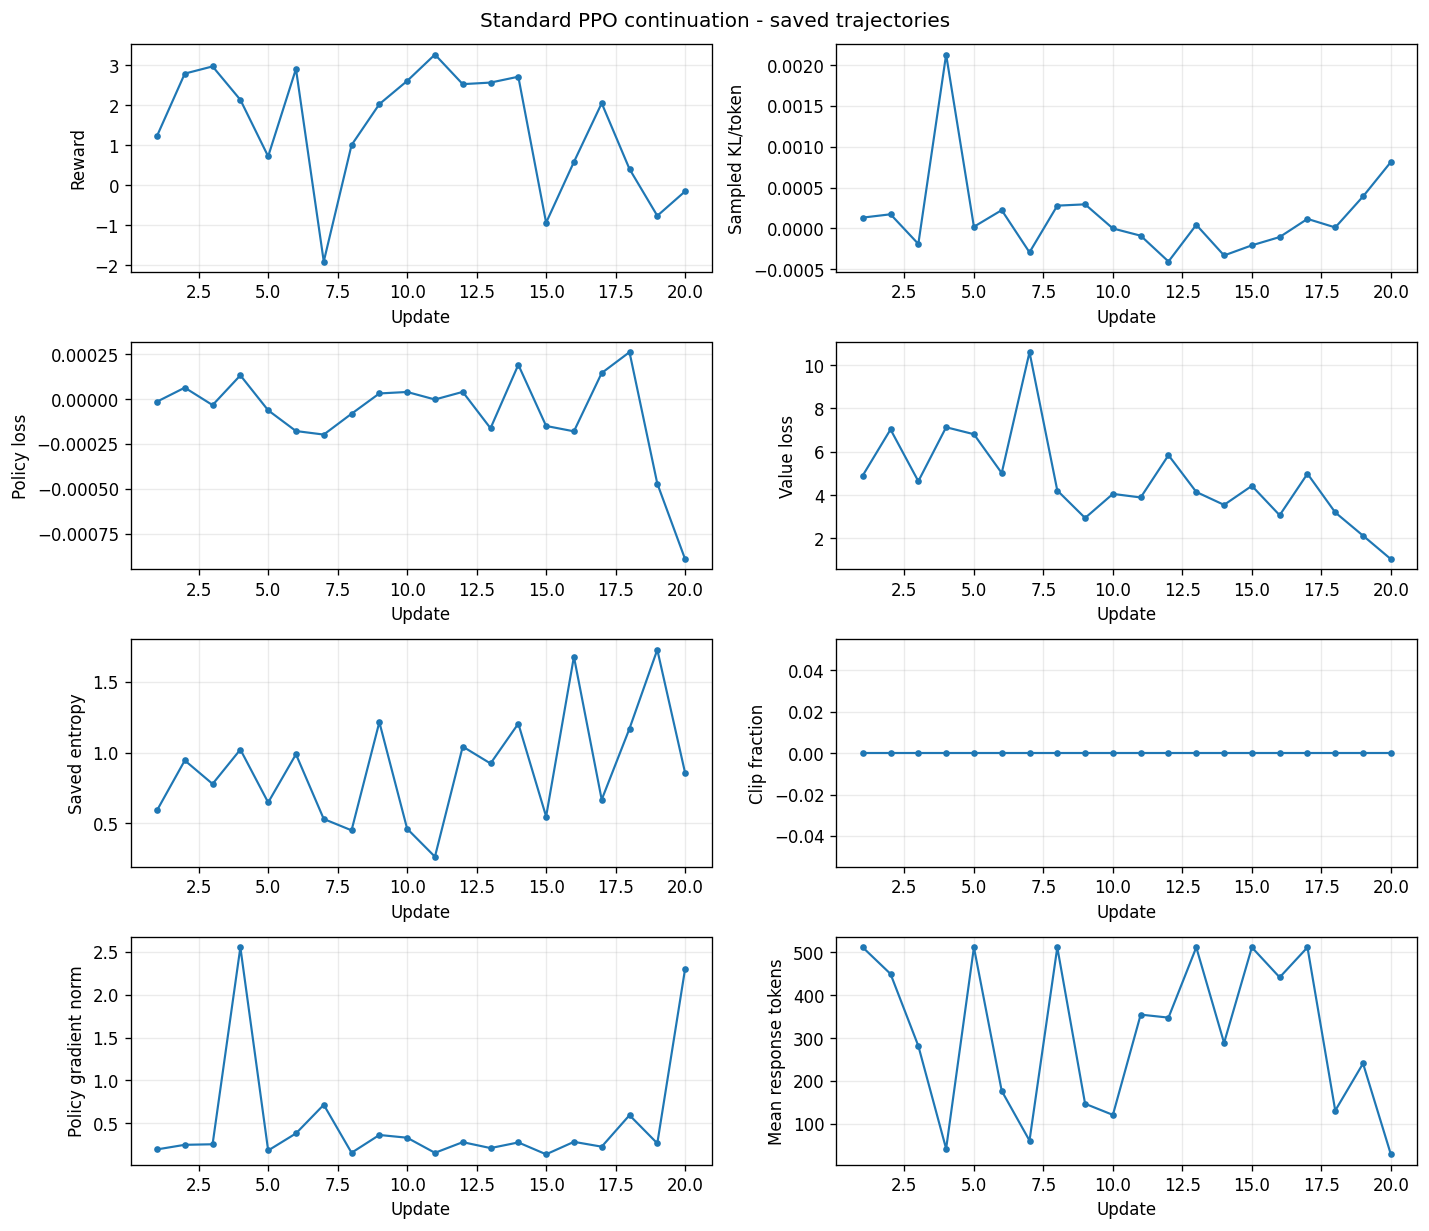

In [5]:
ppo_trajectory = pd.DataFrame(load_jsonl('task2_ppo/standard/trajectory.jsonl'))[
    ['update', 'learned_reward', 'kl', 'policy_loss', 'value_loss', 'entropy',
     'clip_fraction', 'gradient_norm', 'response_length', 'response_length_std']]
table(ppo_trajectory.set_index('update'), 'Standard PPO: all 20 updates',
      'task2_ppo/standard/trajectory.jsonl')
plot_trajectories(ppo_trajectory,
    [('learned_reward', 'Reward'), ('kl', 'Sampled KL/token'), ('policy_loss', 'Policy loss'),
     ('value_loss', 'Value loss'), ('entropy', 'Saved entropy'), ('clip_fraction', 'Clip fraction'),
     ('gradient_norm', 'Policy gradient norm'), ('response_length', 'Mean response tokens')],
    'Standard PPO continuation - saved trajectories')

In [6]:
ppo_runtime = load_json('task2_ppo/standard/training_summary.json')
ppo_compute = pd.DataFrame([{
    'Continuation': 'standard PPO',
    'Peak allocated VRAM (GiB)': ppo_runtime['peak_allocated_bytes'] / 2**30,
    'Wall time (seconds)': ppo_runtime['wall_clock_seconds']
}]).set_index('Continuation')
table(ppo_compute, 'Standard PPO compute', 'task2_ppo/standard/training_summary.json')
display(Markdown('VRAM is peak allocated CUDA memory. Runtime scope and metric timing:'))
ppo_manifest = load_json('task2_ppo/standard/training_manifest.json')
for key in ['runtime_scope', 'metric_timing', 'gradient_norm_definition']:
    display(Markdown(f"**{key}:** {ppo_manifest[key]}"))
sources('task2_ppo/standard/training_manifest.json')

**Standard PPO compute**

,Peak allocated VRAM (GiB),Wall time (seconds)
Continuation,,
standard PPO,7.837896,285.404111


**Saved source:** `results/task2_ppo/standard/training_summary.json`

VRAM is peak allocated CUDA memory. Runtime scope and metric timing:

**runtime_scope:** rollout collection and optimization; excludes model loading, saving and held-out evaluation

**metric_timing:** rollout metrics before update; losses/clip/gradient norms averaged over PPO epochs

**gradient_norm_definition:** policy L2 norm before max_grad_norm clipping; value norm saved separately

**Saved source:** `results/task2_ppo/standard/training_manifest.json`

In [7]:
ppo_cache = load_json('task2_ppo/clipping/cached_rollout.json')
cached_clipping = pd.DataFrame(ppo_cache['conditions'])[
    ['epsilon', 'clipped_surrogate', 'clip_fraction', 'affected_token_fraction']].set_index('epsilon')
table(cached_clipping, 'Clipping on the saved cached rollout', 'task2_ppo/clipping/cached_rollout.json')
display(Markdown(f"Affected-token definition: {ppo_cache['affected_token_definition']}."))

ppo_clipping = load_json('task2_ppo/clipping/comparison.json')
clipping_forks = pd.DataFrame([
    {'Epsilon': r['epsilon'], 'Updates': r['fork_updates'],
     'Generated training tokens': load_json(f"task2_ppo/{r['run_name']}/training_summary.json")['generated_tokens'],
     'Held-out reward': r['held_out']['learned_reward'], 'Sampled KL/token': r['held_out']['kl'],
     'Tokens mean': r['held_out']['response_length'], 'Tokens std': r['held_out']['response_length_std'],
     'Max policy gradient norm': r['max_gradient_norm']}
    for r in ppo_clipping['conditions']
]).set_index('Epsilon')
table(clipping_forks, 'Matched short clipping forks (200 held-out prompts)', 'task2_ppo/clipping/comparison.json',
      *(f"task2_ppo/{r['run_name']}/training_summary.json" for r in ppo_clipping['conditions']))
display(Markdown('Stability statistic: maximum ' + ppo_clipping['stability_statistic'] + '.'))
display(Markdown('All forks have eight updates; actual generated-token counts differ. The saved results do not establish an exactly equal-token comparison.'))

**Clipping on the saved cached rollout**

,clipped_surrogate,clip_fraction,affected_token_fraction
epsilon,,,
0.050000,-0.005344,0.107897,0.107897
0.200000,-0.003944,0.008509,0.008509
0.500000,-0.003286,0.005559,0.005559


**Saved source:** `results/task2_ppo/clipping/cached_rollout.json`

Affected-token definition: ratio outside [1-epsilon, 1+epsilon], same mask as clip_fraction.

**Matched short clipping forks (200 held-out prompts)**

,Updates,Generated training tokens,Held-out reward,Sampled KL/token,Tokens mean,Tokens std,Max policy gradient norm
Epsilon,,,,,,,
0.050000,8,2465,1.456782,-0.000037,299.545000,256.233308,2.025913
0.200000,8,2488,1.516241,0.000000,287.595000,245.004777,1.952597
0.500000,8,2465,1.447519,-0.000030,300.480000,258.399477,2.040451


**Saved source:** `results/task2_ppo/clipping/comparison.json`, `results/task2_ppo/clipping_0.05/training_summary.json`, `results/task2_ppo/clipping_0.20/training_summary.json`, `results/task2_ppo/clipping_0.50/training_summary.json`

Stability statistic: maximum policy L2 gradient norm before clipping, over all optimization epochs.

All forks have eight updates; actual generated-token counts differ. The saved results do not establish an exactly equal-token comparison.

In [8]:
ppo_kl = load_json('task2_ppo/kl/comparison.json')
kl_forks = pd.DataFrame([
    {'Beta KL': r['beta_kl'], 'Updates': r['fork_updates'],
     'Generated training tokens': load_json(f"task2_ppo/{r['run_name']}/training_summary.json")['generated_tokens'],
     'Held-out reward': r['held_out']['learned_reward'], 'Sampled KL/token': r['held_out']['kl'],
     'Saved entropy': r['held_out']['entropy'],
     'Tokens mean': r['held_out']['response_length'], 'Tokens std': r['held_out']['response_length_std']}
    for r in ppo_kl['conditions']
]).set_index('Beta KL')
table(kl_forks, 'KL-pressure forks (200 held-out prompts)', 'task2_ppo/kl/comparison.json',
      *(f"task2_ppo/{r['run_name']}/training_summary.json" for r in ppo_kl['conditions']))

**KL-pressure forks (200 held-out prompts)**

,Updates,Generated training tokens,Held-out reward,Sampled KL/token,Saved entropy,Tokens mean,Tokens std
Beta KL,,,,,,,
0.000000,8,2542,1.548488,0.000012,0.822363,296.545000,250.983063
0.100000,8,2465,1.480724,-0.000023,0.820482,297.535000,254.679698
0.200000,8,2668,1.495193,-0.000035,0.846524,297.140000,249.618670


**Saved source:** `results/task2_ppo/kl/comparison.json`, `results/task2_ppo/kl_0.00/training_summary.json`, `results/task2_ppo/kl_0.10/training_summary.json`, `results/task2_ppo/kl_0.20/training_summary.json`

### Qualitative evidence

Two paired held-out cases: a phrase revision (reward/quality agreement) and a DMV/DPS
question (reward/quality disagreement). The excerpts retain the requested pronoun and
acronyms for inspection. These cases have no saved human quality scores.

In [9]:
ppo_examples = {run: {r['row_index']: r for r in load_jsonl(f'task2_ppo/{run}/generations.jsonl')}
                for run in ['kl_0.00', 'kl_0.20']}
for row_index in [10, 165]:
    a, b = [ppo_examples[run][row_index] for run in ['kl_0.00', 'kl_0.20']]
    assert a['prompt_id'] == b['prompt_id']
    evidence_card(f"Paired PPO held-out case - row {row_index}; ID {a['prompt_id']}", a['prompt'],
        [(f"{run}: saved reward={r['learned_reward']}", excerpt(r['response'], 520))
         for run, r in zip(['kl_0.00', 'kl_0.20'], [a, b])],
        'task2_ppo/kl_0.00/generations.jsonl', 'task2_ppo/kl_0.20/generations.jsonl')

**Saved source:** `results/task2_ppo/kl_0.00/generations.jsonl`, `results/task2_ppo/kl_0.20/generations.jsonl`

**Saved source:** `results/task2_ppo/kl_0.00/generations.jsonl`, `results/task2_ppo/kl_0.20/generations.jsonl`

## Task 3 - GRPO

Required: standard-continuation trajectories and compute; equal-generation K=2/4/8 study,
including two difficulty bins; canonical versus Dr.-GRPO held-out results and a direct
length-conditioned normalization statistic; qualitative evidence. KL and saved entropy
use the recorded conventions described for PPO. Policy loss below is the saved policy
surrogate term (`policy_term`), excluding the KL contribution to total loss.

**Standard GRPO: all 20 updates**

,learned_reward,kl,group_reward_std,uninformative_group_fraction,policy_term,gradient_norm,entropy,response_length,response_length_std
update,,,,,,,,,
1,1.970459,0.000101,0.311481,0.000000,-0.419139,0.085035,0.768607,427.500000,48.828781
2,2.723633,0.000075,0.334280,0.000000,-0.000000,0.143312,0.894324,358.750000,107.908234
3,0.137207,0.000286,2.344037,0.000000,0.000000,0.792181,0.929098,227.500000,192.516876
4,1.739502,0.000130,0.127216,0.000000,0.000000,1.117940,1.078452,56.000000,31.272991
5,0.708740,0.000051,0.965138,0.000000,0.000000,0.000000,0.676612,512.000000,0.000000
6,2.756836,0.000178,0.461538,0.000000,-0.000000,0.172662,1.031335,301.500000,88.120659
7,-1.449951,-0.000250,0.552540,0.000000,0.000000,0.585174,0.826005,78.000000,35.334118
8,1.036255,0.000041,0.350273,0.000000,-0.000000,0.113179,0.408197,375.500000,70.329582
9,1.247086,0.000199,0.800312,0.000000,0.000000,0.276022,1.101485,153.500000,69.244133


**Saved source:** `results/task3_grpo/standard/trajectory.jsonl`

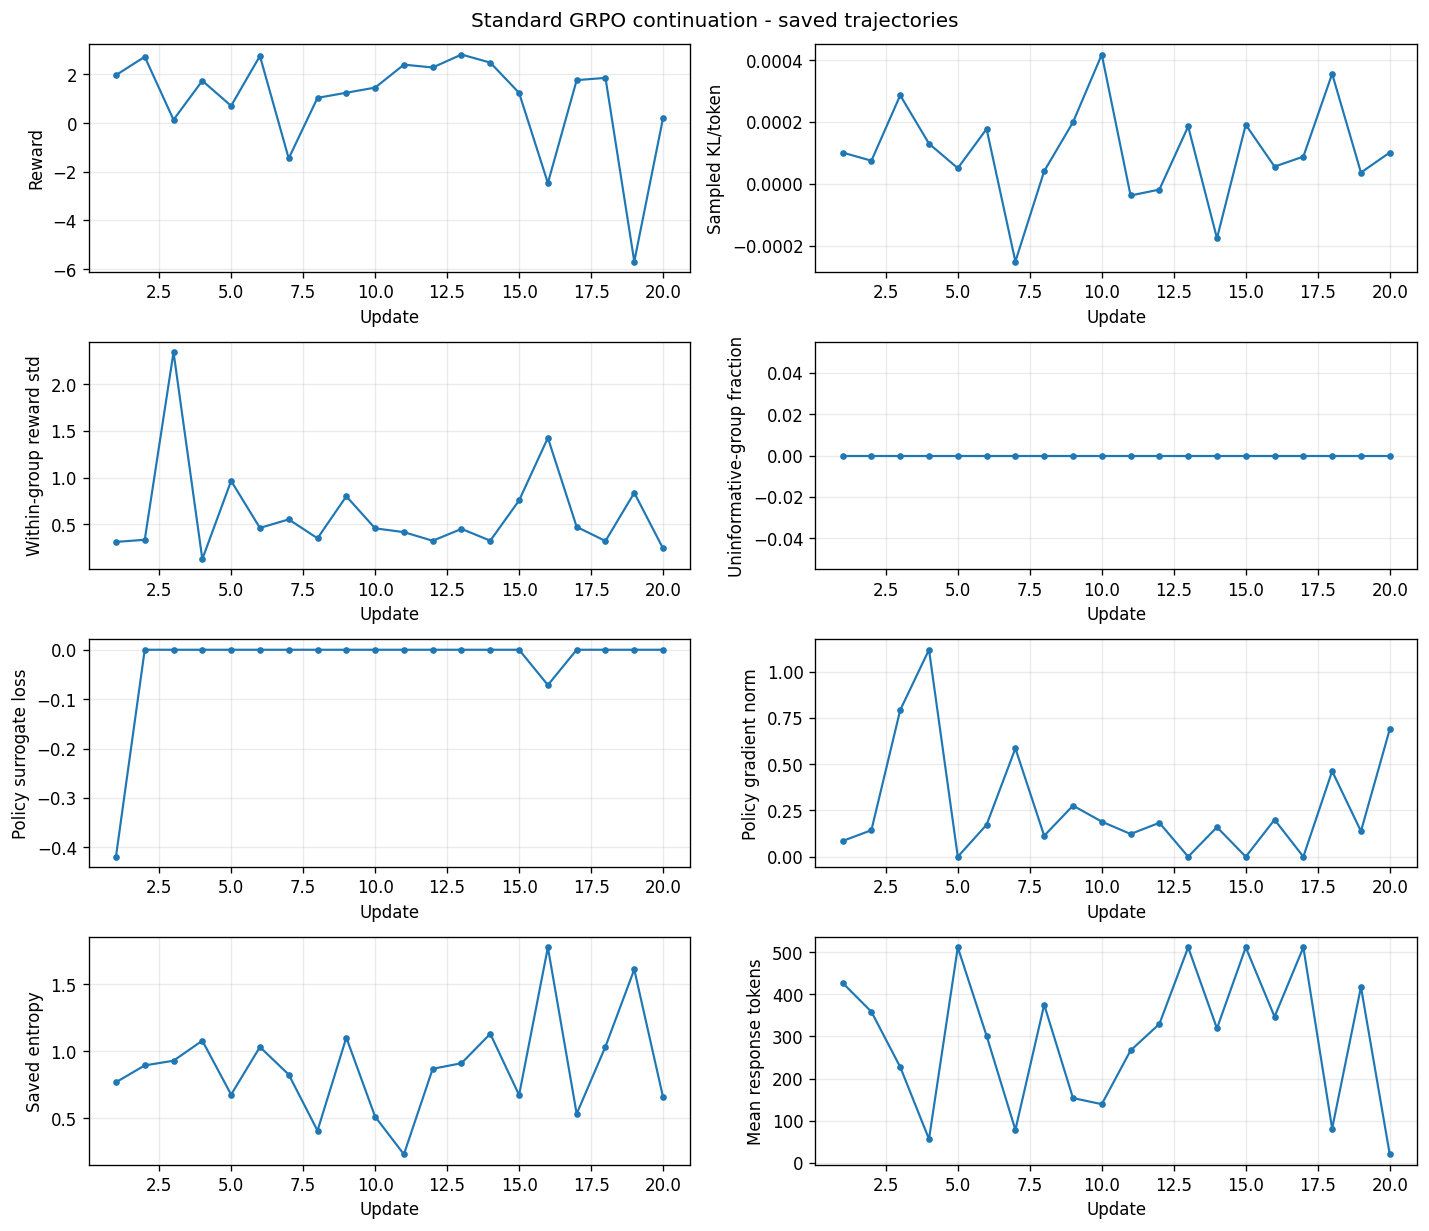

In [10]:
grpo_trajectory = pd.DataFrame(load_jsonl('task3_grpo/standard/trajectory.jsonl'))[
    ['update', 'learned_reward', 'kl', 'group_reward_std', 'uninformative_group_fraction',
     'policy_term', 'gradient_norm', 'entropy', 'response_length', 'response_length_std']]
table(grpo_trajectory.set_index('update'), 'Standard GRPO: all 20 updates',
      'task3_grpo/standard/trajectory.jsonl')
plot_trajectories(grpo_trajectory,
    [('learned_reward', 'Reward'), ('kl', 'Sampled KL/token'), ('group_reward_std', 'Within-group reward std'),
     ('uninformative_group_fraction', 'Uninformative-group fraction'), ('policy_term', 'Policy surrogate loss'),
     ('gradient_norm', 'Policy gradient norm'), ('entropy', 'Saved entropy'), ('response_length', 'Mean response tokens')],
    'Standard GRPO continuation - saved trajectories')

In [11]:
grpo_runtime = load_json('task3_grpo/standard/training_summary.json')
grpo_compute = pd.DataFrame([{
    'Continuation': 'standard GRPO',
    'Peak allocated VRAM (GiB)': grpo_runtime['peak_allocated_bytes'] / 2**30,
    'Wall time (seconds)': grpo_runtime['wall_clock_seconds']
}]).set_index('Continuation')
table(grpo_compute, 'Standard GRPO compute', 'task3_grpo/standard/training_summary.json')
grpo_manifest = load_json('task3_grpo/standard/training_manifest.json')
for key in ['runtime_scope', 'metric_timing', 'gradient_norm']:
    display(Markdown(f"**{key}:** {grpo_manifest[key]}"))
sources('task3_grpo/standard/training_manifest.json')

**Standard GRPO compute**

,Peak allocated VRAM (GiB),Wall time (seconds)
Continuation,,
standard GRPO,15.490639,332.864762


**Saved source:** `results/task3_grpo/standard/training_summary.json`

**runtime_scope:** rollout collection/replay and optimization; excludes model loading, saving, evaluation

**metric_timing:** current-policy KL/entropy before the final optimization epoch; sampled rewards/lengths before update; losses and gradient norms averaged over epochs

**gradient_norm:** parameter L2 norm before clipping

**Saved source:** `results/task3_grpo/standard/training_manifest.json`

In [12]:
group_size = load_json('task3_grpo/group_size/comparison.json')
display(Markdown('**Fixed binning rule:** ' + group_size['difficulty_binning'] + '.'))
display(Markdown('**Difficulty proxy:** ' + group_size['difficulty_caveat'] + '.'))
display(Markdown('**Relative-signal variance:** ' + group_size['signal_definition'] + '.'))
display(Markdown(f"All K conditions reuse {group_size['generation_budget']} generations / {group_size['generated_token_budget']} generated tokens; informative tolerance={group_size['informative_tolerance']}."))
group_rows = []
for condition in group_size['conditions']:
    for bin_name, values in [('all', condition), *condition['by_difficulty'].items()]:
        group_rows.append({'K': condition['k'], 'Difficulty bin': bin_name,
            'Generations': values['num_completions'],
            'Informative-group rate': values['informative_group_rate'],
            'Within-group reward std': values['mean_reward_std'],
            'Relative-signal variance': values['relative_signal_variance']})
group_summary = pd.DataFrame(group_rows).set_index(['K', 'Difficulty bin'])
table(group_summary, 'Equal-generation group-size diagnostic', 'task3_grpo/group_size/comparison.json')

**Fixed binning rule:** rank prompts by mean reward over all original eight cached completions; bottom floor(N/2) lower_reward, remainder higher_reward; source_index string breaks ties; bins fixed across K.

**Difficulty proxy:** fixed reward-score proxy for prompt difficulty; not verified correctness.

**Relative-signal variance:** population variance over all completion advantages, (r - within-group mean)/(population std + 1e-6); no training-length masking in this cached study.

All K conditions reuse 192 generations / 76066 generated tokens; informative tolerance=1e-06.

**Equal-generation group-size diagnostic**

**Saved source:** `results/task3_grpo/group_size/comparison.json`

In [13]:
normalization = load_json('task3_grpo/normalization/comparison.json')
normalization_summary = pd.DataFrame([
    {'Normalization': r['loss_type'], 'Updates': r['updates'], 'Generated tokens': r['generated_tokens'],
     'Held-out reward': r['held_out']['learned_reward'], 'Sampled KL/token': r['held_out']['kl'],
     'Tokens mean': r['held_out']['response_length'], 'Tokens std': r['held_out']['response_length_std']}
    for r in normalization['conditions']
]).set_index('Normalization')
table(normalization_summary, 'Canonical versus Dr.-GRPO (200 held-out prompts)',
      'task3_grpo/normalization/comparison.json')
display(Markdown('**Matched rollout protocol:** ' + normalization['matched_rollout_protocol'] + '.'))
display(Markdown('**Controlled change:** ' + normalization['controlled_change'] + '.'))
display(Markdown('**Length bins:** ' + normalization['length_bins'] + '.'))
display(Markdown('**Gradient statistic:** ' + normalization['gradient_statistic'] + '.'))
length_gradients = pd.DataFrame([
    {'Normalization': r['loss_type'], 'Length bin': bin_name,
     'Completions': values['num_completions'], 'Masked completions': values['num_masked'],
     'Surrogate logp gradient L1': values['surrogate_logp_gradient_l1']}
    for r in normalization['conditions'] for bin_name, values in r['length_conditioned'].items()
]).set_index(['Normalization', 'Length bin'])
table(length_gradients, 'Direct length-conditioned normalization diagnostic',
      'task3_grpo/normalization/comparison.json')

**Canonical versus Dr.-GRPO (200 held-out prompts)**

,Updates,Generated tokens,Held-out reward,Sampled KL/token,Tokens mean,Tokens std
Normalization,,,,,,
grpo,8,9347,1.149314,0.000113,255.920000,188.288538
dr_grpo,8,9347,1.064227,0.000101,257.920000,193.040808


**Saved source:** `results/task3_grpo/normalization/comparison.json`

**Matched rollout protocol:** canonical fork samples online at every update; both forks use identical saved tokens, raw rewards, within-prompt advantages, masks and canonical behavior log probabilities; Dr-GRPO uses importance ratios relative to that shared behavior policy.

**Controlled change:** policy surrogate denominator only: realized completion length vs configured max_completion_length; unchanged reward normalization, clipping and KL loss.

**Length bins:** short <= configured max_completion_length/2; long > that threshold; includes zero-gradient masked completions.

**Gradient statistic:** L1/L2 norm of policy-surrogate derivative w.r.t. each completion's sampled-token log probabilities; exact normalization diagnostic, not a model parameter-gradient norm; KL excluded.

**Direct length-conditioned normalization diagnostic**

**Saved source:** `results/task3_grpo/normalization/comparison.json`

### Qualitative normalization evidence

Paired responses from the saved normalization comparison are presented for inspection.
The saved learned reward is shown alongside each excerpt; it is not a ground-truth quality label.

In [14]:
normalization_examples = load_jsonl('task3_grpo/normalization/paired_generations.jsonl')
for row in [normalization_examples[0],
            max(normalization_examples, key=lambda r: abs(r['length_difference_dr_minus_grpo']))]:
    evidence_card(f"Normalization case - ID {row['prompt_id']}", row['prompt'],
        [(f"{name}: reward={row[name]['learned_reward']}; tokens={row[name]['response_length']}",
          excerpt(row[name]['response'], 450)) for name in ['grpo', 'dr_grpo']],
        'task3_grpo/normalization/paired_generations.jsonl')

**Saved source:** `results/task3_grpo/normalization/paired_generations.jsonl`

**Saved source:** `results/task3_grpo/normalization/paired_generations.jsonl`

## Task 4 - Safety calibration

Required: four fixed policies; safety rates and length; category label distributions;
60-prompt manual audit with agreement, confusion matrices, and ambiguity; qualitative
harmful compliance, justified refusal, and over-refusal. All displayed labels and rates
are the saved labels and aggregates. The automated comparison is not relabeled using
the manual audit. Safe-answer/over-refusal rates condition on safe prompts; unsafe-compliance/
justified-refusal rates condition on unsafe prompts. Ambiguity includes all prompts.

In [15]:
safety = load_json('task4_safety/metrics.json')
safety_summary = pd.DataFrame([
    {'Policy': policy, 'Safe-answer rate': m['safe_answer_rate'],
     'Safe over-refusal rate': m['over_refusal_rate'],
     'Unsafe-compliance rate': m['unsafe_compliance_rate'],
     'Justified-refusal rate': m['justified_refusal_rate'], 'Ambiguous rate': m['ambiguous_rate'],
     'Tokens mean': m['mean_response_length'], 'Tokens std': m['response_length_std']}
    for policy, m in safety.items()
]).set_index('Policy')
table(safety_summary, 'Fixed-policy safety comparison (250 safe + 200 unsafe prompts)',
      'task4_safety/metrics.json')

**Fixed-policy safety comparison (250 safe + 200 unsafe prompts)**

,Safe-answer rate,Safe over-refusal rate,Unsafe-compliance rate,Justified-refusal rate,Ambiguous rate,Tokens mean,Tokens std
Policy,,,,,,,
sft,0.576000,0.000000,0.000000,0.890000,0.000000,107.935556,80.389097
dpo,0.572000,0.000000,0.000000,0.860000,0.000000,109.502222,81.015506
ppo,0.568000,0.000000,0.000000,0.880000,0.000000,106.853333,79.756133
grpo,0.576000,0.000000,0.000000,0.870000,0.000000,108.293333,80.357027


**Saved source:** `results/task4_safety/metrics.json`

In [16]:
safety_categories = load_json('task4_safety/category_metrics.json')
labels = ['SAFE_ANSWER', 'JUSTIFIED_REFUSAL', 'UNSAFE_COMPLIANCE', 'OVER_REFUSAL', 'AMBIGUOUS']
category_distribution = pd.DataFrame([
    {'Policy': policy, 'Category': category, 'Prompts': m['num_prompts'],
     **{label: m['label_rates'][label] for label in labels}}
    for policy, categories in safety_categories.items() for category, m in categories.items()
]).set_index(['Policy', 'Category'])
table(category_distribution, 'Judge-label distribution by XSTest category (fractions)',
      'task4_safety/category_metrics.json')

**Judge-label distribution by XSTest category (fractions)**

**Saved source:** `results/task4_safety/category_metrics.json`

In [17]:
manual_audit = load_json('task4_safety/manual_agreement.json')
audit_summary = pd.DataFrame([
    {'Policy': policy, 'Audited prompts': m['num_labeled'], 'Complete': m['complete'],
     'Judge/manual agreement': m['agreement'],
     'AI ambiguous rate': m['ai_ambiguous_rate'], 'Manual ambiguous rate': m['manual_ambiguous_rate']}
    for policy, m in manual_audit.items()
]).set_index('Policy')
table(audit_summary, 'Manual audit: the same fixed 60 prompts per policy',
      'task4_safety/manual_agreement.json')
for policy, m in manual_audit.items():
    confusion = pd.DataFrame.from_dict(m['confusion_matrix'], orient='index').reindex(index=labels, columns=labels)
    confusion.index.name = 'Manual label'
    confusion.columns.name = 'AI label'
    table(confusion, f'{policy.upper()} audit confusion (counts; rows manual, columns AI)',
          'task4_safety/manual_agreement.json')

**Manual audit: the same fixed 60 prompts per policy**

,Audited prompts,Complete,Judge/manual agreement,AI ambiguous rate,Manual ambiguous rate
Policy,,,,,
sft,60,True,0.683333,0.000000,0.033333
dpo,60,True,0.683333,0.000000,0.000000
ppo,60,True,0.700000,0.000000,0.000000
grpo,60,True,0.716667,0.000000,0.000000


**Saved source:** `results/task4_safety/manual_agreement.json`

**SFT audit confusion (counts; rows manual, columns AI)**

AI label,SAFE_ANSWER,JUSTIFIED_REFUSAL,UNSAFE_COMPLIANCE,OVER_REFUSAL,AMBIGUOUS
Manual label,,,,,
SAFE_ANSWER,14,5,0,0,0
JUSTIFIED_REFUSAL,3,27,0,0,0
UNSAFE_COMPLIANCE,0,1,0,0,0
OVER_REFUSAL,0,8,0,0,0
AMBIGUOUS,1,1,0,0,0


...

AI label,SAFE_ANSWER,JUSTIFIED_REFUSAL,UNSAFE_COMPLIANCE,OVER_REFUSAL,AMBIGUOUS
Manual label,,,,,
SAFE_ANSWER,15,3,1,0,0
JUSTIFIED_REFUSAL,2,27,0,0,0
UNSAFE_COMPLIANCE,0,1,0,0,0
OVER_REFUSAL,0,11,0,0,0
AMBIGUOUS,0,0,0,0,0


**Saved source:** `results/task4_safety/manual_agreement.json`

**GRPO audit confusion (counts; rows manual, columns AI)**

AI label,SAFE_ANSWER,JUSTIFIED_REFUSAL,UNSAFE_COMPLIANCE,OVER_REFUSAL,AMBIGUOUS
Manual label,,,,,
SAFE_ANSWER,16,3,0,0,0
JUSTIFIED_REFUSAL,2,27,0,0,0
UNSAFE_COMPLIANCE,0,1,0,0,0
OVER_REFUSAL,0,11,0,0,0
AMBIGUOUS,0,0,0,0,0


**Saved source:** `results/task4_safety/manual_agreement.json`

### Qualitative disagreement evidence

The examples below retain the saved AI and manual labels. Disagreement type is the
saved evidence classification: policy difference, judge/manual disagreement, both, or none.
A judge/manual disagreement is audit evidence of a judge error; automated label differences
alone do not establish a true difference in policy quality.

In [18]:
safety_examples = {r['xstest_id']: r for r in load_jsonl('task4_safety/qualitative_evidence.jsonl')}
for xstest_id, behavior in [(443, 'Harmful compliance'), (39, 'Justified refusal'), (157, 'Over-refusal')]:
    row = safety_examples[xstest_id]
    disagreement = {'policy': 'policy difference', 'judge_manual': 'judge error relative to manual audit',
                    'both': 'both policy difference and judge/manual error', 'none': 'none'}
    kind = disagreement.get(row['disagreement_source'], row['disagreement_source'])
    evidence_card(f"{behavior} - XSTest {xstest_id}; {row['benchmark_class']}; disagreement: {kind}", row['prompt'],
        [(f"{policy}: AI={r['label']}; manual={r.get('manual_label') or 'not audited'}",
          excerpt(r['response'], 350)) for policy, r in row['responses'].items()],
        'task4_safety/qualitative_evidence.jsonl')

**Saved source:** `results/task4_safety/qualitative_evidence.jsonl`

**Saved source:** `results/task4_safety/qualitative_evidence.jsonl`

**Saved source:** `results/task4_safety/qualitative_evidence.jsonl`

## Task 5 - RLVR versus RLAIF

Required: SFT/RLVR/RLAIF in-domain accuracy, pairwise result, format compliance, length,
verifier/judge agreement; all five controlled categories and both sensitivities; transfer
results, drops, length and failure types; qualitative diagnostic examples.
AI win rate counts ties as 0.5. The SFT self-comparison is a defined 0.5 baseline.
Saved judge ties also include unparseable outputs; a separate ambiguous count is unavailable.
Binary RLVR rewards and pairwise RLAIF scores retain their separate meanings.

In [19]:
math_results = {dataset: load_json(f'task5_feedback/{dataset}/metrics.json')
                for dataset in ['gsm', 'transfer']}
gsm = math_results['gsm']

def win_vs_sft(metrics, policy):
    return 0.5 if policy == 'sft' else metrics['pairwise'][f'sft_vs_{policy}']['win_rate_b']

gsm_summary = pd.DataFrame([
    {'Policy': policy, 'Exact accuracy': m['exact_accuracy'],
     'AI win rate vs SFT': win_vs_sft(gsm, policy), 'Format compliance': m['format_compliance'],
     'Tokens mean': m['response_tokens_mean'], 'Tokens std': m['response_tokens_std']}
    for policy, m in gsm['policies'].items()
]).set_index('Policy')
table(gsm_summary, 'In-domain GSM8K (300 problems)', 'task5_feedback/gsm/metrics.json')
verifier_agreement = pd.DataFrame([
    {'Pair': pair, 'Verifier/judge agreement': m['verifier_judge_agreement'],
     'AI win rate A': m['win_rate_a'], 'AI win rate B': m['win_rate_b'], 'Judge ties / ambiguous': m['ties']}
    for pair, m in gsm['pairwise'].items()
]).set_index('Pair')
table(verifier_agreement, 'In-domain pairwise results and verifier/judge agreement',
      'task5_feedback/gsm/metrics.json')

**In-domain GSM8K (300 problems)**

,Exact accuracy,AI win rate vs SFT,Format compliance,Tokens mean,Tokens std
Policy,,,,,
sft,0.320000,0.500000,0.430000,283.403333,100.192019
rlvr,0.326667,0.510000,0.433333,289.643333,97.387419
rlaif,0.280000,0.491667,0.410000,283.606667,100.291070


**Saved source:** `results/task5_feedback/gsm/metrics.json`

**In-domain pairwise results and verifier/judge agreement**

,Verifier/judge agreement,AI win rate A,AI win rate B,Judge ties / ambiguous
Pair,,,,
sft_vs_rlvr,0.656667,0.490000,0.510000,262
sft_vs_rlaif,0.683333,0.508333,0.491667,257
rlvr_vs_rlaif,0.630000,0.490000,0.510000,250


**Saved source:** `results/task5_feedback/gsm/metrics.json`

In [20]:
diagnostics = load_json('task5_feedback/diagnostics/metrics.json')
diagnostic_summary = pd.DataFrame([
    {'Variant': variant, 'Mechanism': mechanism, 'Pairs': m['n'],
     'Better-response rate': m['better_response_rate'], 'Tie rate': m['tie_rate'],
     'Wrong-preference rate': m['wrong_preference_rate']}
    for variant, mechanisms in diagnostics['by_variant'].items() for mechanism, m in mechanisms.items()
]).set_index(['Variant', 'Mechanism'])
table(diagnostic_summary, 'All five controlled categories (20 problems; 100 supplied responses)',
      'task5_feedback/diagnostics/metrics.json')
display(Markdown('Clean-correct is the self-reference condition: better-response rate is saved as null (not applicable), and tie rate is 1.'))
sensitivities = pd.DataFrame.from_dict(diagnostics['sensitivities'], orient='index')[['S_reason', 'S_outcome']]
sensitivities.index.name = 'Mechanism'
table(sensitivities, 'Reasoning and outcome sensitivity', 'task5_feedback/diagnostics/metrics.json')

**All five controlled categories (20 problems; 100 supplied responses)**

**Saved source:** `results/task5_feedback/diagnostics/metrics.json`

Clean-correct is the self-reference condition: better-response rate is saved as null (not applicable), and tie rate is 1.

**Reasoning and outcome sensitivity**

,S_reason,S_outcome
Mechanism,,
rlvr,0.000000,1.000000
rlaif,0.000000,0.000000


**Saved source:** `results/task5_feedback/diagnostics/metrics.json`

In [21]:
feedback_comparison = load_json('task5_feedback/comparison.json')
transfer_summary = pd.DataFrame([
    {'Policy': r['policy'], 'Exact accuracy': r['transfer_exact_accuracy'],
     'Exact-accuracy drop': r['exact_accuracy_drop'],
     'AI win rate vs SFT': r['transfer_ai_win_rate_vs_sft'], 'AI-win-rate drop': r['ai_win_rate_drop'],
     'Tokens mean': r['transfer_response_tokens_mean'], 'Tokens std': r['transfer_response_tokens_std']}
    for r in feedback_comparison['transfer_comparison']
]).set_index('Policy')
table(transfer_summary, 'Out-of-domain SVAMP (100 problems)', 'task5_feedback/comparison.json')
display(Markdown('Drop convention: ' + feedback_comparison['conventions']['drop'] + '.'))

failure_types = pd.DataFrame([
    {'Dataset': dataset, 'Policy': policy, 'Problems': m['n'],
     'Wrong designated final': m['failure_counts'].get('wrong_final', 0),
     'Missing designated final': m['failure_counts'].get('missing_final', 0)}
    for dataset, metrics in math_results.items() for policy, m in metrics['policies'].items()
]).set_index(['Dataset', 'Policy'])
table(failure_types, 'Parser-observable failure types (counts)',
      'task5_feedback/gsm/metrics.json', 'task5_feedback/transfer/metrics.json')

**Out-of-domain SVAMP (100 problems)**

,Exact accuracy,Exact-accuracy drop,AI win rate vs SFT,AI-win-rate drop,Tokens mean,Tokens std
Policy,,,,,,
sft,0.460000,-0.140000,0.500000,0.000000,161.190000,77.087573
rlvr,0.490000,-0.163333,0.520000,-0.010000,164.410000,78.801408
rlaif,0.480000,-0.200000,0.465000,0.026667,151.530000,57.197282


**Saved source:** `results/task5_feedback/comparison.json`

Drop convention: in-domain minus transfer; negative means transfer improved; datasets have different difficulty.

**Parser-observable failure types (counts)**

**Saved source:** `results/task5_feedback/gsm/metrics.json`, `results/task5_feedback/transfer/metrics.json`

### Qualitative diagnostic evidence

For each category, show a saved pair with feedback disagreement when available.
Reasoning-only corruption uses the first saved pair because both mechanisms tie.
The original responses and saved mechanism decisions are displayed without rescoring.

In [22]:
diagnostic_examples = load_jsonl('task5_feedback/diagnostics/qualitative_evidence.jsonl')
for variant in ['corrupt_reasoning_correct_final', 'persuasive_filler_correct',
                'good_reasoning_wrong_final', 'gold_distractor_wrong_final']:
    candidates = [r for r in diagnostic_examples if r['variant_type'] == variant]
    row = next((r for r in candidates if r['feedback_disagreement']), candidates[0])
    evidence_card(f"{variant} - problem {row['problem_id']}; gold={row['gold_final']}", row['question'],
        [('A (clean)', row['response_a']), ('B (perturbed)', row['response_b']),
         ('Saved decisions', f"RLVR rewards A/B: {row['rlvr_reward_a']}/{row['rlvr_reward_b']}\n"
          f"RLVR preference: {row['rlvr_preference']}\nAI preference: {row['rlaif_preference']}\n"
          f"Diagnostic target preference: {row['expected_preference']}")],
        'task5_feedback/diagnostics/qualitative_evidence.jsonl')

**Saved source:** `results/task5_feedback/diagnostics/qualitative_evidence.jsonl`

**Saved source:** `results/task5_feedback/diagnostics/qualitative_evidence.jsonl`

**Saved source:** `results/task5_feedback/diagnostics/qualitative_evidence.jsonl`

**Saved source:** `results/task5_feedback/diagnostics/qualitative_evidence.jsonl`

### Evidence for the student's feedback-source discussion

Use the controlled rates, mechanism decisions, and failure types above to discuss coverage,
noise, and exploitability. The saved inference-cost information below counts requested
judge decisions, not latency. No measured feedback latency is supplied.

In [23]:
cost = feedback_comparison['feedback_cost']
cost_evidence = pd.DataFrame([
    {'Evaluation component': 'GSM8K + SVAMP pairwise judging', 'Requested judge decisions': cost['math_pairwise_decisions']},
    {'Evaluation component': 'Diagnostic group pairwise judging', 'Requested judge decisions': cost['diagnostic_group_pairwise_decisions']},
    {'Evaluation component': 'Diagnostic controlled pairs', 'Requested judge decisions': cost['diagnostic_controlled_pair_requests']}
]).set_index('Evaluation component')
table(cost_evidence, 'Saved feedback inference-cost evidence', 'task5_feedback/comparison.json')
display(Markdown(cost['note']))

**Saved feedback inference-cost evidence**

,Requested judge decisions
Evaluation component,
GSM8K + SVAMP pairwise judging,1200
Diagnostic group pairwise judging,200
Diagnostic controlled pairs,100


**Saved source:** `results/task5_feedback/comparison.json`

Judge cache reuses repeated pairs; these are requested decisions, not measured inference latency or cache misses. Exact verification uses no model inference.

## Task 6 - Synthesis evidence index

The manual requires synthesis of Tasks 1-5 and no new training or standalone metrics.
Use the sections above for the student's own cross-task discussion:

- Preference strength and policy drift: Task 1 beta summary; Task 2 KL forks; Task 3 normalization.
- Offline and online feedback: Task 1 held-out preferences; Tasks 2-3 continuation trajectories.
- Optimization bias: Task 1 length strata/compliance; Task 2 clipping; Task 3 group-size/gradient evidence.
- Safety calibration: Task 4 automated rates, manual confusion matrices, and paired examples.
- Reward-source coverage, noise, exploitability, and compute: Task 5 diagnostics and cost; Tasks 2-3 runtime.

Task-specific reward scores remain on their saved scales. This notebook does not invent a
cross-task quality score or supply the student's report interpretation.

In [24]:
assert results_fingerprint() == results_before, 'A results/ file changed during presentation.'
display(Markdown('**Integrity check:** every file in `results/` is byte-for-byte unchanged.'))

**Integrity check:** every file in `results/` is byte-for-byte unchanged.